In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import anndata as ad
import h5py

In [6]:
expression_matrix_path = "../data/smfish/expression_matrix_aggregated.tsv"
df = pd.read_csv(expression_matrix_path, sep="\t")
df = df.set_index("label_id")
columns = [col for col in df.columns if col.endswith("spots")]
df_expr = df[columns]
df_expr = df_expr.rename(columns={col: col.split("_")[0] for col in df_expr.columns})

In [7]:
print(df)

          Arx_spots  Brn3_spots  Bsx_AP203_spots  COpsin1_spots  \
label_id                                                          
1               5.0         9.0              0.0            9.0   
2              27.0        10.0              1.0            3.0   
3              18.0        17.0              0.0            5.0   
4              24.0         7.0              0.0            3.0   
5              22.0        30.0              1.0            4.0   
...             ...         ...              ...            ...   
11479          12.0        11.0              2.0            2.0   
11483           2.0         5.0              0.0            1.0   
11486           1.0         8.0              0.0            2.0   
11492           9.0         9.0              1.0            4.0   
11493           1.0         1.0              4.0            1.0   

          Dbx_AP080_spots  FoxQ2_AP249_spots  GoOpsin1_AP127_spots  \
label_id                                                  

In [73]:
df_expr.describe()

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
count,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000
mean,8.873660,9.443321,3.031977,2.955912,1.427899,2.365862,3.814499,6.648950,5.255380,7.122419,3.958961,21.035027,5.576196,10.163196,4.955825,10.338852,11.404287
std,12.790244,8.746828,6.460549,3.833336,4.060384,6.642470,10.485696,7.899346,8.896751,6.174915,6.722527,12.887838,6.947750,8.636159,9.652234,10.725029,8.241889
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000,2.000000,1.000000,3.000000,0.000000,12.000000,1.000000,4.000000,1.000000,3.000000,5.000000
50%,4.000000,7.000000,1.000000,2.000000,0.000000,1.000000,0.000000,4.000000,2.000000,6.000000,2.000000,19.000000,3.000000,8.000000,2.000000,7.000000,10.000000
75%,11.000000,14.000000,3.000000,4.000000,1.000000,2.000000,3.000000,9.000000,6.000000,9.000000,5.000000,28.000000,8.000000,14.000000,5.000000,14.000000,15.000000
max,194.000000,67.000000,117.000000,78.000000,76.000000,150.000000,173.000000,96.000000,140.000000,82.000000,92.000000,148.000000,111.000000,72.000000,185.000000,124.000000,110.000000


Text(0.5, 1.0, 'Distribution of raw counts')

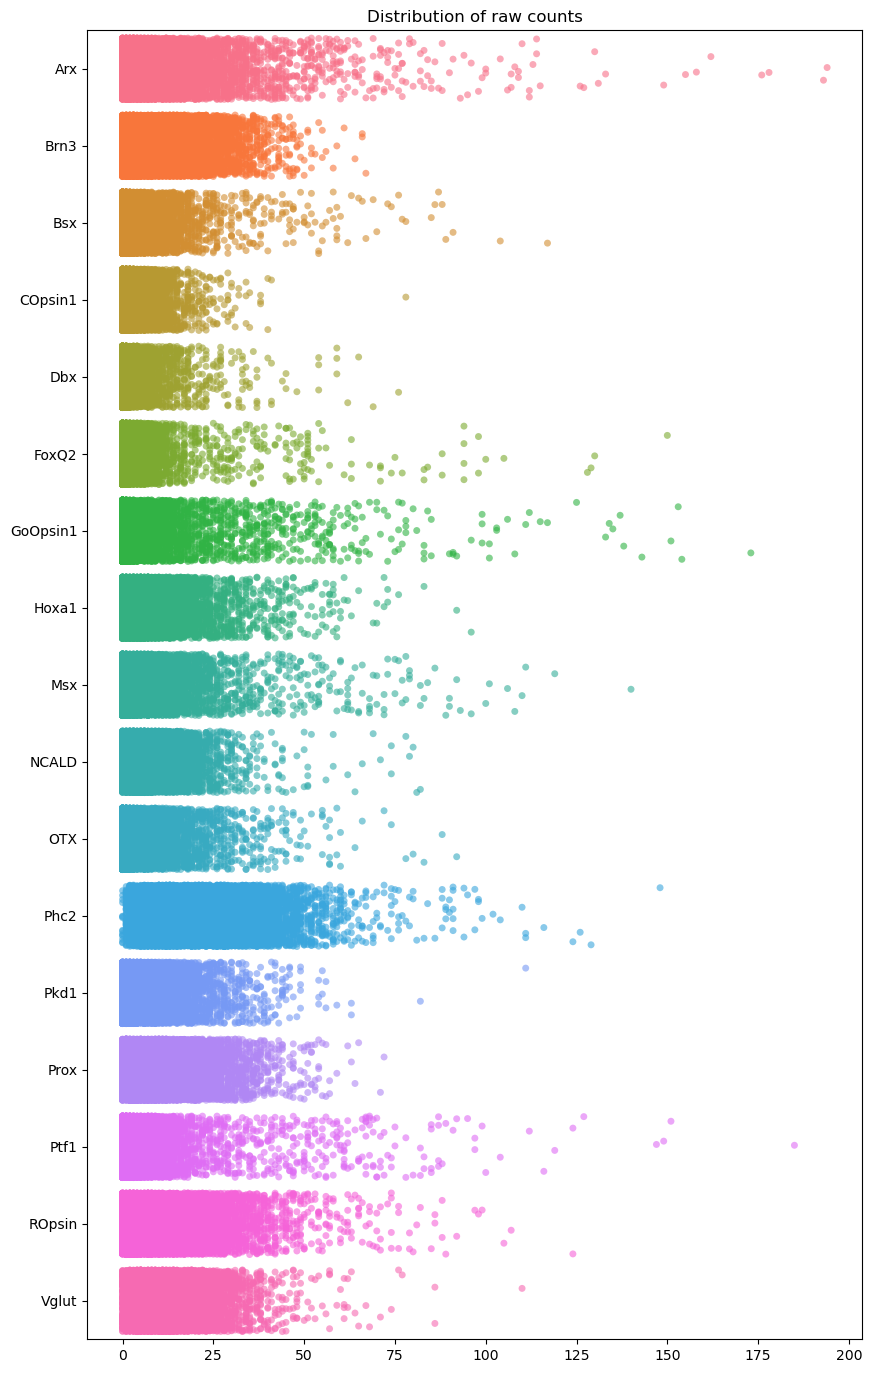

In [74]:
plt.figure(figsize=(10, 1 * len(df_expr.columns)))
sns.stripplot(df_expr, jitter=0.4, alpha=0.6, orient="h")
plt.title("Distribution of raw counts")

Text(0.5, 1.0, 'Distribution of raw counts')

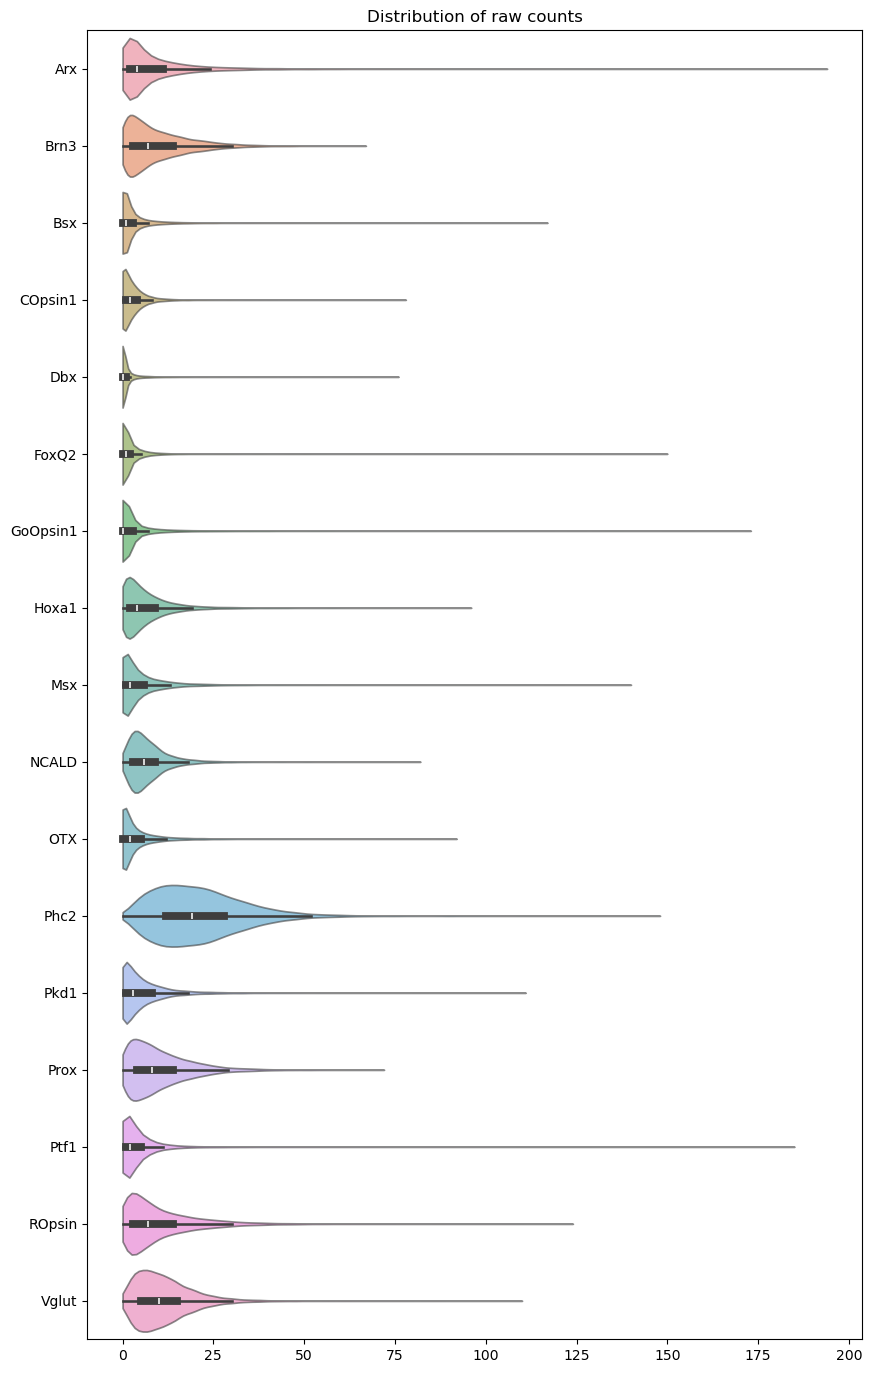

In [75]:
plt.figure(figsize=(10, 1 * len(df_expr.columns)))
sns.violinplot(df_expr, alpha=0.6, orient="h", cut=0)
plt.title("Distribution of raw counts")

In [ ]:
df_expr

In [76]:
count_threshold = 20
df_thr_expr = df_expr
df_thr_expr[df_expr <= count_threshold] = 0

In [77]:
df_thr_expr

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,22.0,0.0,0.0,25.0,0.0
1,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.0,0.0,0.0,0.0,0.0,34.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.0,0.0,0.0,0.0,0.0,30.0
3,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,26.0
4,22.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11472,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0
11473,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.0,0.0,0.0,0.0,0.0,0.0
11474,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,0.0,0.0,0.0,0.0,0.0
11475,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0


In [85]:
def percentile_norm(expr, pmin, pmax, eps=1e-10):
    """Percentile normalization of an expression vector. Values are clipped to [0, 1] range
    Args:
        expr: expression vector
        pmin: in percents
        pmax: in percents
        eps: _description_. Defaults to 1e-10.

    Returns:
        _description_
    """

    pmin = np.percentile(expr, pmin)
    pmax = np.percentile(expr, pmax)
    return np.clip(((expr.astype(np.float32) - pmin) / (pmax - pmin + eps)), a_min=0, a_max=1)

In [86]:
df_norm_expr = pd.DataFrame()
df_norm_expr.index = df_thr_expr.index
for col in df_thr_expr.columns:
    df_norm_expr[col] = percentile_norm(df_thr_expr[col], 0, 99)

In [87]:
df_thr_expr.describe()

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
count,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000,11477.000000
mean,3.966890,3.279603,0.761000,0.189074,0.282739,0.701229,1.958439,1.648166,1.646946,0.956609,1.016293,14.549795,1.221051,3.296332,1.662194,4.377625,3.321774
std,13.321243,9.279526,5.722491,2.348210,3.173274,6.195283,10.237444,7.526978,8.470982,5.536630,5.912691,17.468756,6.151822,9.398479,9.479231,11.715101,9.458798
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,28.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,194.000000,67.000000,117.000000,78.000000,76.000000,150.000000,173.000000,96.000000,140.000000,82.000000,92.000000,148.000000,111.000000,72.000000,185.000000,124.000000,110.000000


In [88]:
df_norm_expr

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
0,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.383333,0.666667,0.000000,0.0,0.510204,0.000000
1,0.450000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.766667,0.000000,0.000000,0.0,0.000000,0.894737
2,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.516667,0.000000,0.000000,0.0,0.000000,0.789474
3,0.400000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.566667,0.000000,0.000000,0.0,0.000000,0.684211
4,0.366667,0.789474,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11472,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.366667,0.000000,0.000000,0.0,0.000000,0.000000
11473,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.550000,0.000000,0.000000,0.0,0.000000,0.000000
11474,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.450000,0.000000,0.000000,0.0,0.000000,0.000000
11475,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.483333,0.000000,0.000000,0.0,0.000000,0.000000


In [89]:
df_thr_expr

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,22.0,0.0,0.0,25.0,0.0
1,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.0,0.0,0.0,0.0,0.0,34.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.0,0.0,0.0,0.0,0.0,30.0
3,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,26.0
4,22.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11472,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0
11473,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.0,0.0,0.0,0.0,0.0,0.0
11474,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.0,0.0,0.0,0.0,0.0,0.0
11475,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,0.0


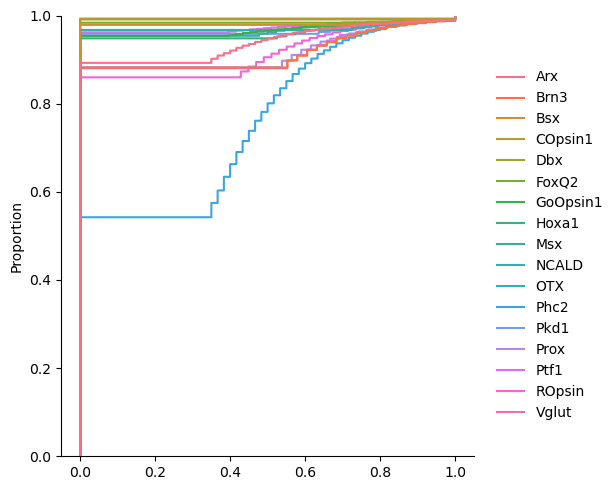

In [92]:
sns.displot(df_norm_expr,  kind="ecdf")


Arx
Brn3
Bsx
COpsin1
Dbx
FoxQ2
GoOpsin1
Hoxa1
Msx
NCALD
OTX
Phc2
Pkd1
Prox
Ptf1
ROpsin
Vglut


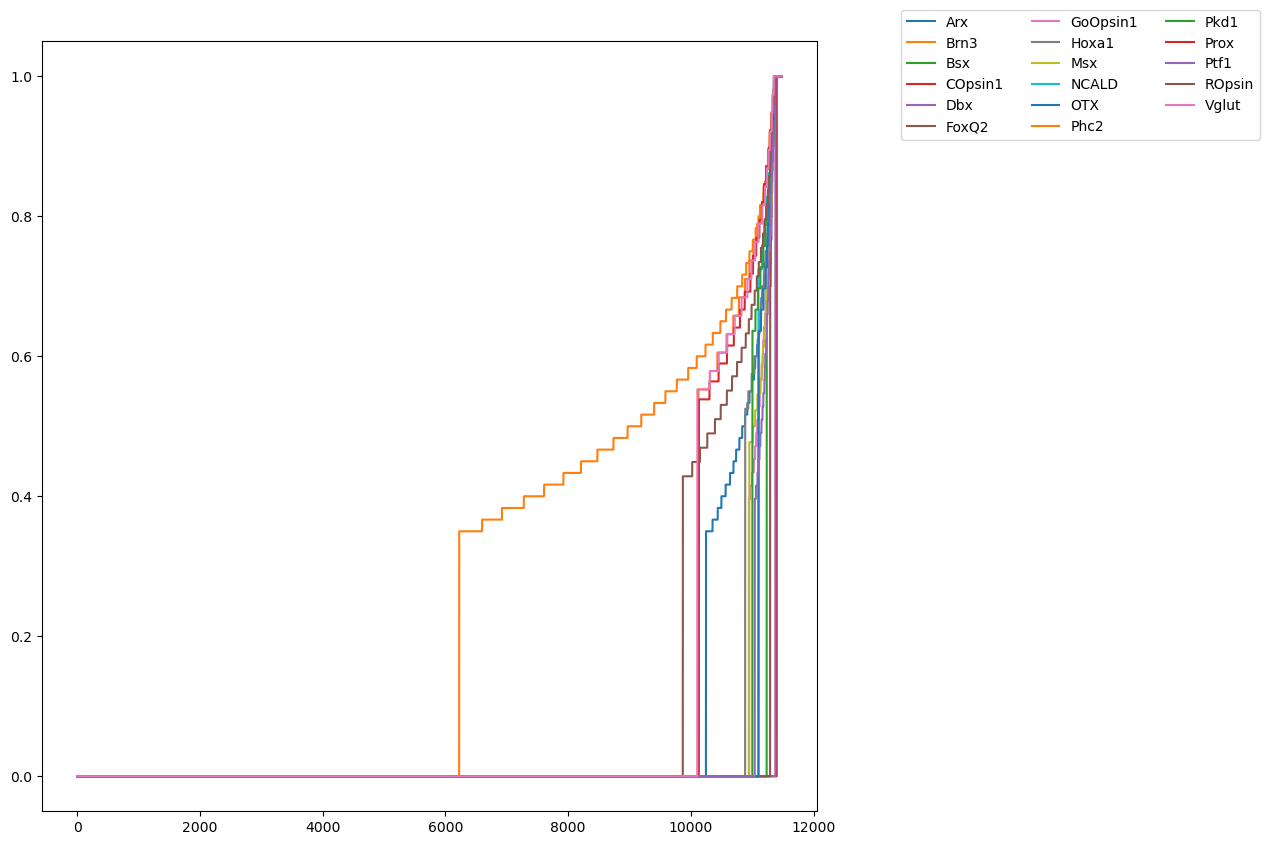

In [93]:
def plot_cumulative_expression(expr, gene_name):
    expr_sorted = np.sort(expr)
#     plt.figure()
    plt.plot(expr_sorted, label=gene_name)
    plt.legend(bbox_to_anchor=(1.1, 1.05), ncol=3)
#     plt.show()

plt.figure(figsize=(10, 10))
for col in df_norm_expr.columns:
    print(col)
    
    plot_cumulative_expression(df_norm_expr[col], col)

In [ ]:
plt.figure(figsize=(10, 1 * len(df_expr.columns)))
sns.stripplot(df_expr, jitter=0.4, alpha=0.6, orient="h")

In [116]:
df_expr.head()

,Arx,Brn3,Bsx,COpsin1,Dbx,FoxQ2,GoOpsin1,Hoxa1,Msx,NCALD,OTX,Phc2,Pkd1,Prox,Ptf1,ROpsin,Vglut
0,0.0,0.0,0.0,0.0,22.0,0.0,0.0,0.0,0.0,0.0,0.0,23.0,22.0,0.0,0.0,25.0,0.0
1,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,46.0,0.0,0.0,0.0,0.0,34.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.0,0.0,0.0,0.0,0.0,30.0
3,24.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,26.0
4,22.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<BarContainer object of 17 artists>

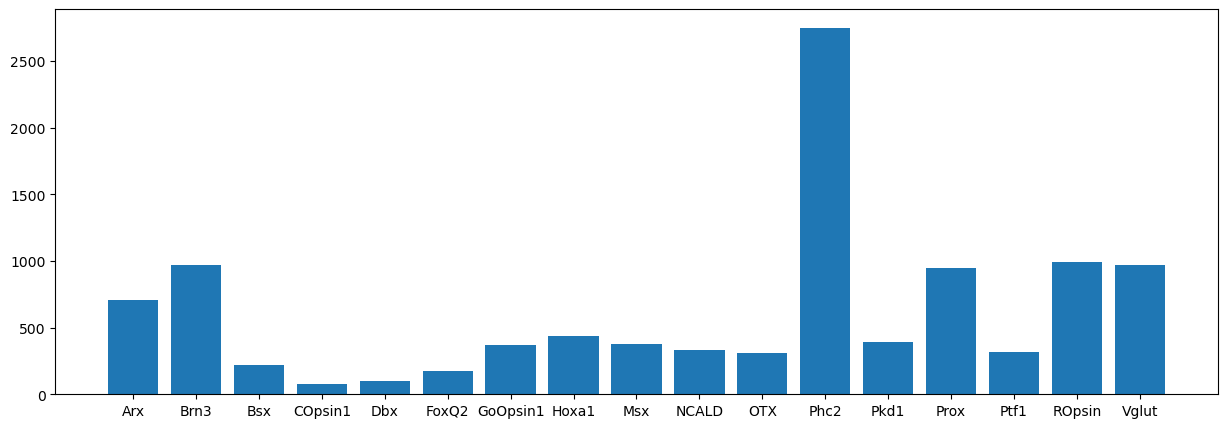

In [95]:
plt.figure(figsize=(15, 5))
plt.bar(df_norm_expr.columns, df_norm_expr.sum(axis=0))

In [96]:
df_bin_expr = (df_norm_expr > 0).astype(np.int16)

<BarContainer object of 17 artists>

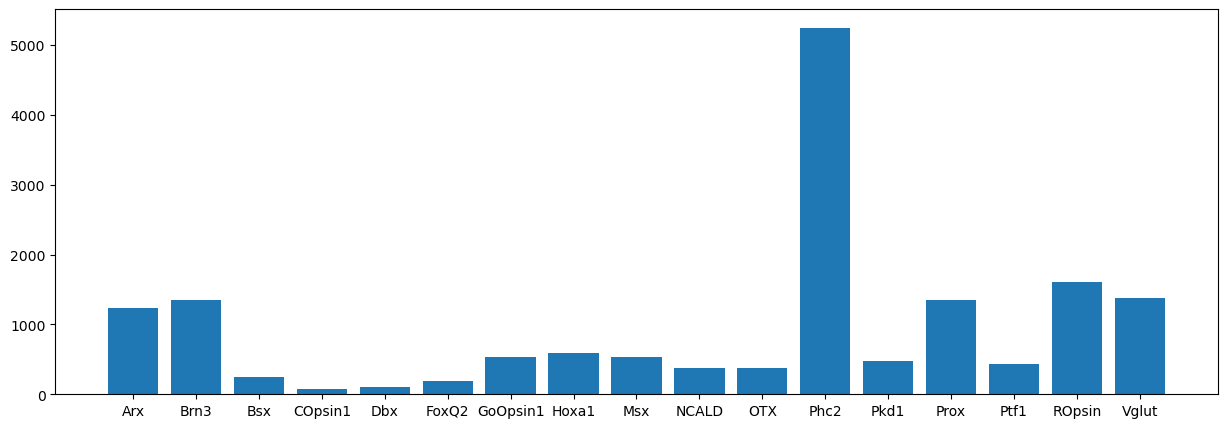

In [97]:
plt.figure(figsize=(15, 5))
plt.bar(df_bin_expr.columns, df_bin_expr.sum(axis=0))

In [105]:
df_bin_expr.sum(axis=1).value_counts()

0     3846
1     3732
2     1972
3      914
4      425
5      213
6      125
7       78
8       51
9       42
10      41
11      22
12      11
13       3
15       1
14       1
Name: count, dtype: int64

Text(0, 0.5, 'Number of cells')

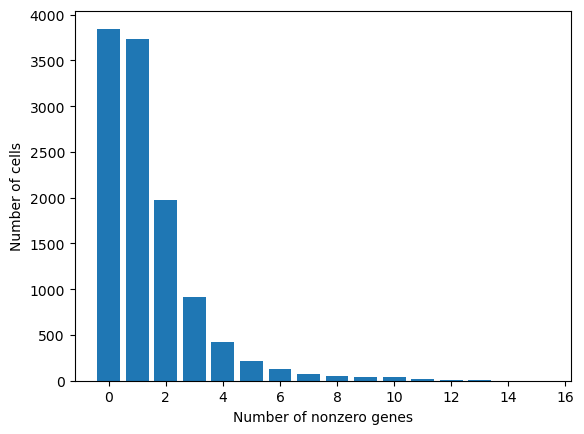

In [114]:
plt.bar(df_bin_expr.sum(axis=1).value_counts().index, df_bin_expr.sum(axis=1).value_counts())
plt.xlabel("Number of nonzero genes")
plt.ylabel("Number of cells")